# CampusPulse — Hypothesis Testing (Textbook Methods Only)
### `06_hypothesis_testing_textbook.ipynb`

This notebook tests six hypotheses on the cleaned CampusPulse data using **only** the methods in the two course PDFs:

| PDF section | Method | Used for |
|---|---|---|
| 6.2 | Central Limit Theorem (n ≥ 30 ⇒ x̄ approximately normal) | Justifies the z-tests below |
| 8.1 – 8.3 | Five-step procedure, critical-value approach and *p*-value approach | Every test |
| 9.1 | z-test for the difference of two means, large independent samples | Tests 1, 2, 4 |
| 11.3 | F-test for equality of two variances | Test 3 |
| 11.1 | Chi-square test for independence | Tests 5, 6 |

**Left out on purpose** (not in the PDFs): non-parametric tests, ANOVA, paired tests, regression, multiple-testing corrections. The small-sample t-tests (8.4, 9.2) are also not needed because every group compared has n ≥ 30.

**The five-step procedure** (Sections 8.1 and 8.3), printed for every test below:

1. State H₀ and Hₐ.
2. Identify the test statistic and its distribution.
3. Compute the test statistic from the data.
4. Find the rejection region (critical value) — and, equivalently, the *p*-value.
5. Decide: reject H₀ if the statistic falls in the rejection region (or if *p* ≤ α), and state the conclusion in plain language.

**Significance level:** α = 0.05 for all tests. Critical values and tail areas are obtained with `scipy.stats` in place of the printed tables (the PDFs note that *p*-values are normally found with software).

### Interpretation and assumptions note
All six tests use an individual significance level of 5%; no family-wise multiple-testing correction is applied. The two-sample large-sample Z procedures require independent observations and sufficiently large samples. The classical F-test additionally assumes normally distributed populations. For Pearson chi-square independence tests, check expected (not observed) cell counts; if the expected-frequency condition is not met, the approximation may be unreliable. Statistical association does not establish causation.

## 0 · Setup

In [1]:
import os
from pathlib import Path

# Find the project root (works from the root or from a sub-folder such as src/)
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "data" / "raw").is_dir():
    raise FileNotFoundError("Could not locate the project data/raw directory")
os.chdir(PROJECT_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats      # used ONLY to replace the printed z / F / chi-square tables

plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "#f8f9fa", "axes.grid": True, "grid.color": "white", "font.size": 10})
Path("data/analytics").mkdir(parents=True, exist_ok=True)

ALPHA = 0.05
RESULTS = []    # one row per test, filled by the functions below

df_ls = pd.read_csv("data/processed/lifestyle_clean.csv")
df_uc = pd.read_csv("data/processed/uci_clean.csv")
df_mh = pd.read_csv("data/processed/mental_health_clean.csv")
print(f"Lifestyle {df_ls.shape} | UCI {df_uc.shape} | Mental Health {df_mh.shape}")

Lifestyle (2000, 7) | UCI (1044, 37) | Mental Health (100, 13)


### 0.1 · The three test functions

Each function follows the five steps and prints every intermediate number so the arithmetic can be checked by hand.

- **`z_test_two_means`** — Section 9.1: Z = [(x̄₁ − x̄₂) − D₀] / √(s₁²/n₁ + s₂²/n₂), standard normal; sample standard deviations are used because σ is unknown.
- **`f_test_two_variances`** — Section 11.3: F = s₁²/s₂², with df₁ = n₁ − 1 and df₂ = n₂ − 1; two-tailed rejection region F ≤ F₁₋α/₂ or F ≥ Fα/₂.
- **`chi_square_independence`** — Section 11.1: E = (row total × column total)/n, χ² = Σ(O − E)²/E, df = (I − 1)(J − 1), always right-tailed.

In [ ]:
def fp(p):
    """Format a p-value for printing."""
    if p == 0: return "< 1e-300"
    return f"{p:.2e}" if p < 0.001 else f"{p:.4f}"

def z_test_two_means(tid, question, x1, x2, name1, name2, unit="", alpha=ALPHA):
    x1, x2 = pd.Series(x1).dropna(), pd.Series(x2).dropna()
    n1, n2 = len(x1), len(x2)
    m1, m2 = x1.mean(), x2.mean()
    s1, s2 = x1.std(ddof=1), x2.std(ddof=1)
    # Section 9.1 requires both samples large (n >= 30) and independent
    assert n1 >= 30 and n2 >= 30, "large-sample z-test needs n >= 30 in both groups"
    se = np.sqrt(s1**2 / n1 + s2**2 / n2)
    Z = ((m1 - m2) - 0) / se
    z_crit = stats.norm.ppf(1 - alpha / 2)
    p = 2 * stats.norm.sf(abs(Z))                       # two-tailed: double the tail area (Section 8.3)
    reject = abs(Z) >= z_crit

    print(f"{'='*78}\n{tid}: {question}\n{'='*78}")
    print(f"Step 1  H0: μ1 − μ2 = 0   vs   Ha: μ1 − μ2 ≠ 0   (two-tailed, α = {alpha})")
    print(f"        population 1 = {name1}, population 2 = {name2}")
    print("Step 2  Large independent samples (n1, n2 >= 30) ⇒ Z = [(x̄1 − x̄2) − 0] / √(s1²/n1 + s2²/n2) ~ standard normal")
    print(f"Step 3  {name1}: n = {n1}, x̄ = {m1:.4f}, s = {s1:.4f}")
    print(f"        {name2}: n = {n2}, x̄ = {m2:.4f}, s = {s2:.4f}")
    print(f"        s1²/n1 = {s1**2:.5f}/{n1} = {s1**2 / n1:.6f}    s2²/n2 = {s2**2:.5f}/{n2} = {s2**2 / n2:.6f}")
    print(f"        standard error = √{s1**2 / n1 + s2**2 / n2:.6f} = {se:.5f}")
    print(f"        Z = ({m1 - m2:.4f}) / {se:.5f} = {Z:.3f}")
    print(f"Step 4  critical values ±z_{alpha / 2} = ±{z_crit:.3f}  → reject if Z <= −{z_crit:.3f} or Z >= {z_crit:.3f}")
    print(f"        p-value = 2 × (tail area) = {fp(p)}")
    print(f"Step 5  |Z| = {abs(Z):.3f} {'>=' if reject else '<'} {z_crit:.3f}  and  p {'<=' if p <= alpha else '>'} α  →  {'REJECT H0' if reject else 'FAIL TO REJECT H0'}")
    RESULTS.append(dict(test=tid, question=question, method="z-test, two means (9.1)", statistic=f"Z = {Z:.2f}",
                        critical=f"±{z_crit:.3f}", p_value=p, reject_H0=reject,
                        sample_result=f"x̄({name1}) − x̄({name2}) = {m1 - m2:+.3f}{unit}"))
    return dict(Z=Z, z_crit=z_crit, p=p, reject=reject, diff=m1 - m2, kind="z")

def f_test_two_variances(tid, question, x1, x2, name1, name2, alpha=ALPHA):
    x1, x2 = pd.Series(x1).dropna(), pd.Series(x2).dropna()
    n1, n2 = len(x1), len(x2)
    v1, v2 = x1.var(ddof=1), x2.var(ddof=1)
    F = v1 / v2
    df1, df2 = n1 - 1, n2 - 1
    f_hi = stats.f.ppf(1 - alpha / 2, df1, df2)          # F_{α/2}   (upper critical value)
    f_lo = stats.f.ppf(alpha / 2, df1, df2)              # F_{1−α/2} (lower critical value)
    p = 2 * min(stats.f.sf(F, df1, df2), stats.f.cdf(F, df1, df2))
    reject = (F <= f_lo) or (F >= f_hi)

    print(f"{'='*78}\n{tid}: {question}\n{'='*78}")
    print(f"Step 1  H0: σ1² = σ2²   vs   Ha: σ1² ≠ σ2²   (two-tailed, α = {alpha})")
    print(f"        population 1 = {name1}, population 2 = {name2}")
    print("Step 2  F = s1² / s2², F-distribution with df1 = n1 − 1 and df2 = n2 − 1 (populations assumed normal)")
    print(f"Step 3  s1² = {v1:.5f} (n1 = {n1}),  s2² = {v2:.5f} (n2 = {n2})")
    print(f"        F = {v1:.5f} / {v2:.5f} = {F:.3f},   df1 = {df1}, df2 = {df2}")
    print(f"Step 4  lower critical value F_{{1−α/2}} = {f_lo:.3f},  upper critical value F_{{α/2}} = {f_hi:.3f}")
    print(f"        reject if F <= {f_lo:.3f} or F >= {f_hi:.3f}     (two-tailed p-value = {fp(p)})")
    print("        Note: the PDF's F-table stops at df1 = 60 / df2 = 100 (upper 0.025 value there = 1.56). With larger df the")
    print("        true critical value is smaller, so any F above 1.56 is also in the rejection region.")
    print(f"Step 5  F = {F:.3f} → {'REJECT H0' if reject else 'FAIL TO REJECT H0'}")
    RESULTS.append(dict(test=tid, question=question, method="F-test, two variances (11.3)", statistic=f"F = {F:.2f}",
                        critical=f"≤{f_lo:.3f} or ≥{f_hi:.3f}", p_value=p, reject_H0=reject,
                        sample_result=f"s²({name1}) = {v1:.4f} vs s²({name2}) = {v2:.4f}"))
    return dict(F=F, f_lo=f_lo, f_hi=f_hi, df1=df1, df2=df2, p=p, reject=reject, kind="F")

def chi_square_independence(tid, question, table, h0_text, ha_text, sample_result, alpha=ALPHA):
    O = table.values.astype(float)
    R = O.sum(axis=1, keepdims=True); C = O.sum(axis=0, keepdims=True); n = O.sum()
    E = R @ C / n                                            # E = (row total × column total) / n
    contrib = (O - E) ** 2 / E
    chi2 = contrib.sum()
    df = (O.shape[0] - 1) * (O.shape[1] - 1)
    crit = stats.chi2.ppf(1 - alpha, df)                     # right-tailed critical value
    p = stats.chi2.sf(chi2, df)
    reject = chi2 >= crit
    cond_ok = (E >= 5).all()

    print(f"{'='*78}\n{tid}: {question}\n{'='*78}")
    print(f"Step 1  H0: {h0_text}\n        Ha: {ha_text}   (α = {alpha})")
    print("Step 2  χ² = Σ (O − E)² / E,  chi-square distribution with df = (I − 1)(J − 1);  always right-tailed")
    print(f"        Condition: every expected cell count should be at least 5  →  minimum expected count = {E.min():.2f}  → {'OK' if cond_ok else 'NOT MET — chi-square approximation may be unreliable'}")
    print("Step 3  Observed table (with totals):")
    shown = table.copy(); shown["Total"] = shown.sum(axis=1); shown.loc["Total"] = shown.sum()
    print(shown.to_string())
    print("        Expected counts E = (row total × column total) / n:")
    print(pd.DataFrame(E, index=table.index, columns=table.columns).round(2).to_string())
    print("        Contributions (O − E)² / E:")
    print(pd.DataFrame(contrib, index=table.index, columns=table.columns).round(3).to_string())
    print(f"        χ² = {' + '.join(f'{v:.3f}' for v in contrib.ravel())} = {chi2:.3f},   df = {df}")
    print(f"Step 4  critical value χ²_{alpha} (df = {df}) = {crit:.3f}  → rejection region [{crit:.3f}, ∞);   p-value = {fp(p)}")
    print(f"Step 5  χ² = {chi2:.3f} {'>=' if reject else '<'} {crit:.3f}  and  p {'<=' if p <= alpha else '>'} α  →  {'REJECT H0' if reject else 'FAIL TO REJECT H0'}")
    RESULTS.append(dict(test=tid, question=question, method="Chi-square independence (11.1)", statistic=f"χ² = {chi2:.2f} (df={df})",
                        critical=f"≥{crit:.3f}", p_value=p, reject_H0=reject, sample_result=sample_result))
    return dict(chi2=chi2, crit=crit, df=df, p=p, reject=reject, kind="chi", table=table, E=E, expected_condition_met=cond_ok)

---
## 1 · Lifestyle dataset — Tests 1 to 3

Population 1 = **High-stress** students (n = 1029), population 2 = **Low-stress** students (n = 297). The two groups are different students, so the samples are independent, and both are far above the n ≥ 30 rule from the Central Limit Theorem section.

In [3]:
hi = df_ls[df_ls["stress_level"] == "High"]
lo = df_ls[df_ls["stress_level"] == "Low"]
print(f"High stress n = {len(hi)},  Low stress n = {len(lo)}")

High stress n = 1029,  Low stress n = 297


### Test 1 · Do High- and Low-stress students study a different number of hours?

In [ ]:
t1 = z_test_two_means("Test 1", "Mean study hours per day: High vs Low stress",
                      hi["study_hours_per_day"], lo["study_hours_per_day"], "High", "Low", unit=" h")
if t1["reject"]:
    direction = "more" if t1["diff"] > 0 else "fewer"
    print(f"\nConclusion: Reject H0 at α=0.05. There is evidence that mean study hours differ. "
          f"The High group averages {abs(t1['diff']):.2f} hours {direction} than the Low group in this sample.")
else:
    print("\nConclusion: Fail to reject H0 at α=0.05. The sample does not provide sufficient evidence of a difference in mean study hours.")

### Test 2 · Do High- and Low-stress students have a different mean GPA?

In [ ]:
t2 = z_test_two_means("Test 2", "Mean GPA: High vs Low stress", hi["gpa"], lo["gpa"], "High", "Low", unit=" GPA points")
if t2["reject"]:
    direction = "higher" if t2["diff"] > 0 else "lower"
    print(f"\nConclusion: Reject H0 at α=0.05. There is evidence that mean GPA differs. "
          f"The High group has a {abs(t2['diff']):.2f}-point {direction} mean GPA than the Low group in this sample.")
else:
    print("\nConclusion: Fail to reject H0 at α=0.05. The sample does not provide sufficient evidence of a difference in mean GPA.")

### Test 3 · Is GPA equally *consistent* in the two groups?
This asks about **spread**, not the mean, so the F-test for two variances (Section 11.3) is the right tool. It assumes the populations are normal; GPA is roughly symmetric here (skew ≈ 0), so the assumption is reasonable.

In [ ]:
t3 = f_test_two_variances("Test 3", "Variance of GPA: High vs Low stress", hi["gpa"], lo["gpa"], "High", "Low")
if t3["reject"]:
    direction = "greater" if t3["F"] > 1 else "smaller"
    print(f"\nConclusion: Reject H0 at α=0.05. There is evidence that GPA variances differ; "
          f"the sample variance for the High group is {direction} than for the Low group.")
else:
    print("\nConclusion: Fail to reject H0 at α=0.05. The sample does not provide sufficient evidence that GPA variances differ.")
print("F-test limitation: the classical variance-ratio test assumes normally distributed populations and can be sensitive to non-normality.")

---
## 2 · UCI dataset — Tests 4 and 5 (math course only)

Many students appear in **both** the math and Portuguese files. Pooling the two would count the same person twice and break the "independent samples" requirement, so only the **math** file is used.

In [7]:
math_all = df_uc[df_uc["subject"] == "math"]
math_nd  = math_all[math_all["possible_dropout"] == 0]      # dropouts have G3 = 0, which is not a real final grade
print(f"Math students: {len(math_all)}  (non-dropouts: {len(math_nd)}, dropouts: {int(math_all['possible_dropout'].sum())})")

Math students: 395  (non-dropouts: 357, dropouts: 38)


### Test 4 · Do students with prior failures have a different mean final grade (G3)?
Population 1 = no past failures, population 2 = at least one past failure. Dropouts (G3 = 0) are excluded here and analysed separately in Test 5.

In [ ]:
no_fail = math_nd[math_nd["failures"] == 0]["g3"]
fail    = math_nd[math_nd["failures"] >= 1]["g3"]
t4 = z_test_two_means("Test 4", "Mean final grade G3 (math): no failures vs ≥1 failure", no_fail, fail, "0 failures", "≥1 failure", unit=" grade points")
if t4["reject"]:
    direction = "higher" if t4["diff"] > 0 else "lower"
    print(f"\nConclusion: Reject H0 at α=0.05. There is evidence of a difference in mean G3. "
          f"The no-failure group has a {abs(t4['diff']):.2f}-point {direction} mean grade than the ≥1-failure group in this sample.")
else:
    print("\nConclusion: Fail to reject H0 at α=0.05. The sample does not provide sufficient evidence of a difference in mean G3.")

### Test 5 · Is dropping out independent of having prior failures?
Both factors are categorical, so the chi-square test for independence (Section 11.1) applies. All observed counts must be at least 5 — checked inside the function.

In [ ]:
tab5 = pd.crosstab(math_all["failures"] >= 1, math_all["possible_dropout"]).reindex(index=[False, True], columns=[0, 1], fill_value=0)
tab5.index = ["0 failures", "≥1 failure"]; tab5.columns = ["Not dropout", "Dropout"]
rate0 = tab5.loc["0 failures", "Dropout"] / tab5.loc["0 failures"].sum()
rate1 = tab5.loc["≥1 failure", "Dropout"] / tab5.loc["≥1 failure"].sum()
t5 = chi_square_independence("Test 5", "Dropout vs prior failures (math)", tab5,
                             "dropout and prior failures are independent", "dropout and prior failures are not independent",
                             f"dropout rate {rate0:.1%} (0 failures) vs {rate1:.1%} (≥1 failure)")
if not t5["expected_condition_met"]:
    print("\nConclusion withheld: expected-frequency condition is not met; use an appropriate alternative or combine categories only with substantive justification.")
elif t5["reject"]:
    print(f"\nConclusion: Reject H0 at α=0.05. There is evidence of association between dropout flag and prior failures (rates: {rate0:.1%} vs {rate1:.1%}).")
else:
    print("\nConclusion: Fail to reject H0 at α=0.05. The sample does not provide sufficient evidence of an association between dropout flag and prior failures.")

---
## 3 · Mental Health dataset — Test 6

### Test 6 · Are depression and anxiety independent?
n = 100 students; both variables are yes/no. All four observed cells are at least 5, so the chi-square condition holds.

> Two other natural questions — *treatment-seeking vs depression* (one cell is 0) and *depression vs CGPA band* (sparse cells) — **fail** the chi-square condition, so the textbook test cannot be used on them. They are deliberately not tested here.

In [ ]:
tab6 = pd.crosstab(df_mh["depression"], df_mh["anxiety"]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
tab6.index = ["No depression", "Depression"]; tab6.columns = ["No anxiety", "Anxiety"]
a_dep   = tab6.loc["Depression", "Anxiety"] / tab6.loc["Depression"].sum()
a_nodep = tab6.loc["No depression", "Anxiety"] / tab6.loc["No depression"].sum()
t6 = chi_square_independence("Test 6", "Depression vs anxiety", tab6,
                             "depression and anxiety are independent", "depression and anxiety are not independent",
                             f"anxiety rate {a_dep:.1%} (depressed) vs {a_nodep:.1%} (not depressed)")
if not t6["expected_condition_met"]:
    print("\nConclusion withheld: expected-frequency condition is not met; the chi-square approximation may be unreliable.")
elif t6["reject"]:
    print(f"\nConclusion: Reject H0 at α=0.05. There is evidence of association between self-reported depression and anxiety (anxiety rates: {a_dep:.1%} vs {a_nodep:.1%}).")
else:
    print("\nConclusion: Fail to reject H0 at α=0.05. The sample does not provide sufficient evidence of an association between self-reported depression and anxiety.")

---
## 4 · Sanity check against library routines
The hand-coded formulas above should give exactly the same numbers as SciPy's built-in versions. (This is only a check on the arithmetic — the analysis itself uses the textbook formulas.)

In [11]:
for tid, r in [("Test 5", t5), ("Test 6", t6)]:
    chi2_lib, p_lib, dof_lib, _ = stats.chi2_contingency(r["table"].values, correction=False)
    print(f"{tid}: χ² textbook = {r['chi2']:.4f} | SciPy = {chi2_lib:.4f}   p textbook = {fp(r['p'])} | SciPy = {fp(p_lib)}   match: {np.isclose(r['chi2'], chi2_lib)}")

# Welch/unpooled z via SciPy's t-test on large samples gives essentially the same statistic (t ≈ z when n is large)
for tid, a, b in [("Test 1", hi["study_hours_per_day"], lo["study_hours_per_day"]),
                  ("Test 2", hi["gpa"], lo["gpa"]), ("Test 4", no_fail, fail)]:
    t_lib = stats.ttest_ind(a, b, equal_var=False).statistic
    print(f"{tid}: Z by textbook formula ≈ unpooled t from SciPy = {t_lib:.3f}")
f_lib = hi["gpa"].var(ddof=1) / lo["gpa"].var(ddof=1)
print(f"Test 3: F = s1²/s2² = {f_lib:.4f}")

Test 5: χ² textbook = 25.3261 | SciPy = 25.3261   p textbook = 4.84e-07 | SciPy = 4.84e-07   match: True
Test 6: χ² textbook = 7.2888 | SciPy = 7.2888   p textbook = 0.0069 | SciPy = 0.0069   match: True
Test 1: Z by textbook formula ≈ unpooled t from SciPy = 69.504
Test 2: Z by textbook formula ≈ unpooled t from SciPy = 29.369
Test 4: Z by textbook formula ≈ unpooled t from SciPy = 6.234
Test 3: F = s1²/s2² = 1.6295


---
## 5 · Pictures of the rejection regions
Same style as the figures in the PDFs: the shaded area is the rejection region, the star/arrow marks the computed statistic. For the very large Z values the arrow sits at the edge of the plot and the true value is written beside it.

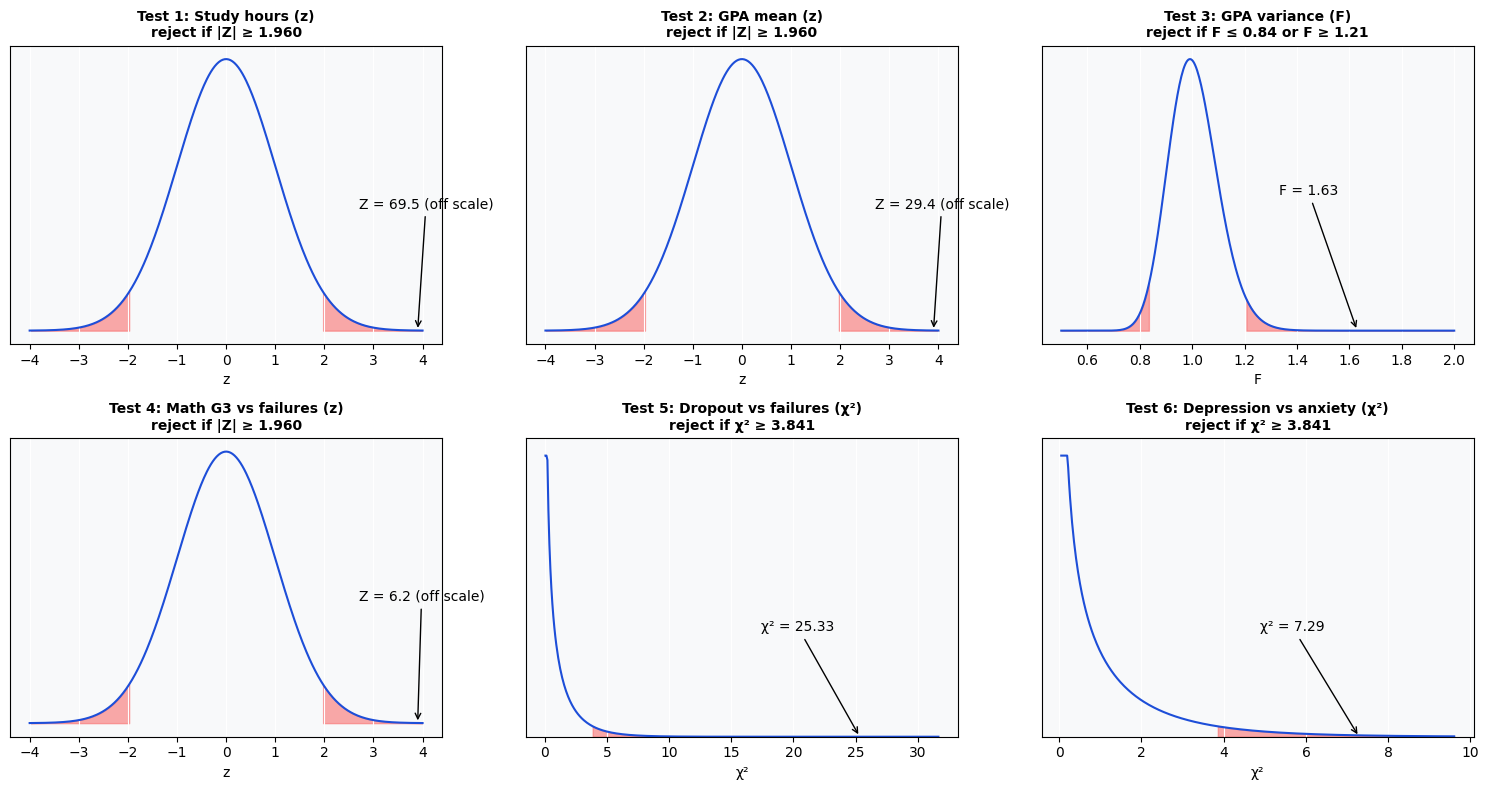

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8)); axes = axes.ravel()
results = [("Test 1", t1), ("Test 2", t2), ("Test 3", t3), ("Test 4", t4), ("Test 5", t5), ("Test 6", t6)]
titles = {"Test 1": "Study hours (z)", "Test 2": "GPA mean (z)", "Test 3": "GPA variance (F)",
          "Test 4": "Math G3 vs failures (z)", "Test 5": "Dropout vs failures (χ²)", "Test 6": "Depression vs anxiety (χ²)"}
for ax, (tid, r) in zip(axes, results):
    if r["kind"] == "z":
        x = np.linspace(-4, 4, 400); y = stats.norm.pdf(x); zc = r["z_crit"]
        ax.plot(x, y, color="#1d4ed8"); ax.fill_between(x, y, where=(x <= -zc), color="#f87171", alpha=.6); ax.fill_between(x, y, where=(x >= zc), color="#f87171", alpha=.6)
        pos = np.clip(r["Z"], -3.9, 3.9)
        ax.annotate(f"Z = {r['Z']:.1f}" + (" (off scale)" if abs(r["Z"]) > 3.9 else ""), xy=(pos, 0.0), xytext=(pos - 1.2, 0.18), arrowprops=dict(arrowstyle="->", color="black"))
        ax.set_xlabel("z"); ax.set_title(f"{tid}: {titles[tid]}\nreject if |Z| ≥ {zc:.3f}", fontsize=10, fontweight="bold")
    elif r["kind"] == "F":
        x = np.linspace(0.5, 2.0, 400); y = stats.f.pdf(x, r["df1"], r["df2"])
        ax.plot(x, y, color="#1d4ed8"); ax.fill_between(x, y, where=(x <= r["f_lo"]), color="#f87171", alpha=.6); ax.fill_between(x, y, where=(x >= r["f_hi"]), color="#f87171", alpha=.6)
        ax.annotate(f"F = {r['F']:.2f}", xy=(r["F"], 0), xytext=(r["F"] - .3, y.max() * .5), arrowprops=dict(arrowstyle="->", color="black"))
        ax.set_xlabel("F"); ax.set_title(f"{tid}: {titles[tid]}\nreject if F ≤ {r['f_lo']:.2f} or F ≥ {r['f_hi']:.2f}", fontsize=10, fontweight="bold")
    else:
        top = max(r["chi2"] * 1.25, r["crit"] * 2.5); x = np.linspace(0.05, top, 400)
        y = np.minimum(stats.chi2.pdf(x, r["df"]), 0.8)          # df = 1 density explodes near 0, so cap it for display
        ax.plot(x, y, color="#1d4ed8"); ax.fill_between(x, y, where=(x >= r["crit"]), color="#f87171", alpha=.6)
        ax.annotate(f"χ² = {r['chi2']:.2f}", xy=(r["chi2"], 0), xytext=(r["chi2"] - top * .25, 0.3), arrowprops=dict(arrowstyle="->", color="black"))
        ax.set_ylim(0, 0.85); ax.set_xlabel("χ²"); ax.set_title(f"{tid}: {titles[tid]}\nreject if χ² ≥ {r['crit']:.3f}", fontsize=10, fontweight="bold")
    ax.set_yticks([])
plt.tight_layout(); plt.savefig("data/analytics/textbook_rejection_regions.png", dpi=130, bbox_inches="tight"); plt.show()

---
## 6 · Summary of all six tests

In [13]:
summary = pd.DataFrame(RESULTS)
summary["decision (α = 0.05)"] = np.where(summary["reject_H0"], "Reject H0", "Fail to reject H0")
summary["p_value"] = summary["p_value"].map(fp)
summary = summary[["test", "question", "method", "statistic", "critical", "p_value", "decision (α = 0.05)", "sample_result"]]
pd.set_option("display.max_colwidth", 70); pd.set_option("display.width", 250)
display(summary)
summary.to_csv("data/analytics/textbook_hypothesis_results.csv", index=False)
print("✅ Saved data/analytics/textbook_hypothesis_results.csv")

,test,question,method,statistic,critical,p_value,decision (α = 0.05),sample_result
0,Test 1,Mean study hours per day: High vs Low stress,"z-test, two means (9.1)",Z = 69.50,±1.960,< 1e-300,Reject H0,x̄(High) − x̄(Low) = +2.911 h
1,Test 2,Mean GPA: High vs Low stress,"z-test, two means (9.1)",Z = 29.37,±1.960,1.35e-189,Reject H0,x̄(High) − x̄(Low) = +0.445 GPA points
2,Test 3,Variance of GPA: High vs Low stress,"F-test, two variances (11.3)",F = 1.63,≤0.837 or ≥1.207,6.54e-07,Reject H0,s²(High) = 0.0756 vs s²(Low) = 0.0464
3,Test 4,Mean final grade G3 (math): no failures vs ≥1 failure,"z-test, two means (9.1)",Z = 6.23,±1.960,4.55e-10,Reject H0,x̄(0 failures) − x̄(≥1 failure) = +2.371 grade points
4,Test 5,Dropout vs prior failures (math),Chi-square independence (11.1),χ² = 25.33 (df=1),≥3.841,4.84e-07,Reject H0,dropout rate 5.8% (0 failures) vs 24.1% (≥1 failure)
5,Test 6,Depression vs anxiety,Chi-square independence (11.1),χ² = 7.29 (df=1),≥3.841,0.0069,Reject H0,anxiety rate 51.4% (depressed) vs 24.6% (not depressed)


✅ Saved data/analytics/textbook_hypothesis_results.csv


---
## 7 · Reading the results responsibly

- **Large samples make tiny differences "significant".** With n in the hundreds or thousands, Z values become huge. Always quote the size of the difference (hours, GPA points, percentage points) next to the decision.
- **Association, not causation.** Rejecting independence or equality of means does not say *why* the groups differ.
- **The Lifestyle data is synthetic**, so Tests 1–3 describe how the data were generated, not real students.
- **Assumptions used:** independent samples and n ≥ 30 (z-tests); normal populations (F-test); every observed cell count ≥ 5 (chi-square). The UCI tests use the math file only so the same student is not counted twice.
- **Questions the textbook methods cannot answer here:** comparing all three stress levels at once, before/after (G1 vs G3) comparisons on the same students, and rank-based correlations. Those would need methods beyond the two PDFs.